In [1]:
# 🚀 Day 28 — Kmeans Clustering


## AI/ML Engineer Bootcamp

Project overview
- Goal: Group customers with similar spending behavior.
- Algorithm: K-Means clustering.
- Type: Unsupervised Machine Learning.
- Dataset: Sample customer data created in Python.
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Create a sample customer dataset
# Annual income is expressed in thousands of currency units
# Spending score is an illustrative score between 0 and 100
data = {
    "CustomerID": list(range(1, 16)),
    "Annual_Income": [
        15, 18, 20, 22, 25,
        40, 42, 45, 48, 50,
        70, 75, 78, 85, 90
    ],
    "Spending_Score": [
        80, 75, 85, 78, 82,
        40, 45, 42, 38, 44,
        20, 25, 18, 15, 22
    ]
}

# Convert the dictionary into a Pandas DataFrame
df = pd.DataFrame(data)

# Display the first five customer records
df.head()

,CustomerID,Annual_Income,Spending_Score
0,1,15,80
1,2,18,75
2,3,20,85
3,4,22,78
4,5,25,82


In [4]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Display count, mean, standard deviation, minimum, and maximum
print("\nStatistical summary:")
print(df.describe())

Dataset shape: (15, 3)

Column names:
['CustomerID', 'Annual_Income', 'Spending_Score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      15 non-null     int64
 1   Annual_Income   15 non-null     int64
 2   Spending_Score  15 non-null     int64
dtypes: int64(3)
memory usage: 492.0 bytes

Statistical summary:
       CustomerID  Annual_Income  Spending_Score
count   15.000000       15.00000       15.000000
mean     8.000000       48.20000       47.266667
std      4.472136       25.82413       25.874606
min      1.000000       15.00000       15.000000
25%      4.500000       23.50000       23.500000
50%      8.000000       45.00000       42.000000
75%     11.500000       72.50000       76.500000
max     15.000000       90.00000       85.000000


In [5]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check whether customer IDs are duplicated
print(
    "Duplicate Customer IDs:",
    df["CustomerID"].duplicated().sum()
)

Missing values:
CustomerID        0
Annual_Income     0
Spending_Score    0
dtype: int64

Duplicate rows: 0
Duplicate Customer IDs: 0


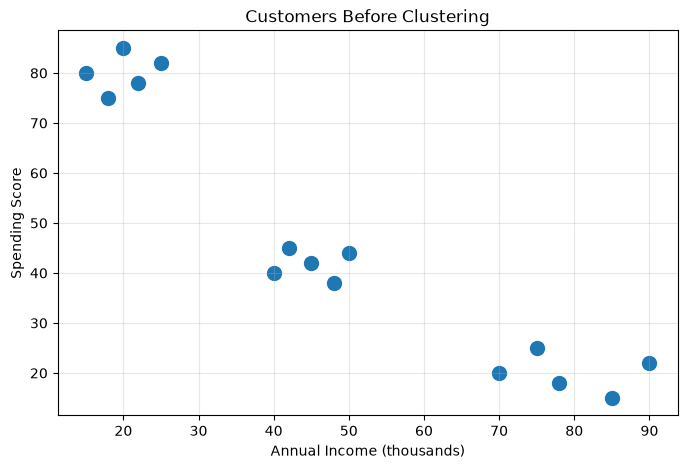

In [6]:
# Create a figure with a specified width and height
plt.figure(figsize=(8, 5))

# Plot income against spending score
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    s=100
)

# Add a descriptive title and axis labels
plt.title("Customers Before Clustering")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")

# Display a grid to make the plot easier to read
plt.grid(True, alpha=0.3)

# Display the plot
plt.show()

In [7]:
# Select the two meaningful numerical features
# Exclude CustomerID because it is only an identifier
X = df[["Annual_Income", "Spending_Score"]]

# Display the selected features
print(X.head())

   Annual_Income  Spending_Score
0             15              80
1             18              75
2             20              85
3             22              78
4             25              82


In [8]:
# Create a StandardScaler object
scaler = StandardScaler()

# Learn each feature's mean and standard deviation,
# then transform the data to a comparable scale
X_scaled = scaler.fit_transform(X)

# Display the first five standardized observations
print("First five scaled rows:")
print(X_scaled[:5].round(2))

First five scaled rows:
[[-1.33  1.31]
 [-1.21  1.11]
 [-1.13  1.51]
 [-1.05  1.23]
 [-0.93  1.39]]


In [9]:
# Create an empty list to store inertia values
inertias = []

# Test cluster counts from 1 to 8
k_values = range(1, 9)

# Train one K-Means model for each value of K
for k in k_values:

    # Create a K-Means model with k clusters
    model = KMeans(
        n_clusters=k,
        init="k-means++",  # Select starting centroids intelligently
        n_init=10,         # Try 10 different initializations
        random_state=42    # Make results reproducible
    )

    # Fit the model to the standardized data
    model.fit(X_scaled)

    # Store the sum of squared distances to cluster centroids
    inertias.append(model.inertia_)

# Print each K value and its corresponding inertia
for k, inertia in zip(k_values, inertias):
    print(f"K = {k}, Inertia = {inertia:.3f}")

K = 1, Inertia = 30.000
K = 2, Inertia = 7.557
K = 3, Inertia = 0.847
K = 4, Inertia = 0.501
K = 5, Inertia = 0.402
K = 6, Inertia = 0.313
K = 7, Inertia = 0.246
K = 8, Inertia = 0.232


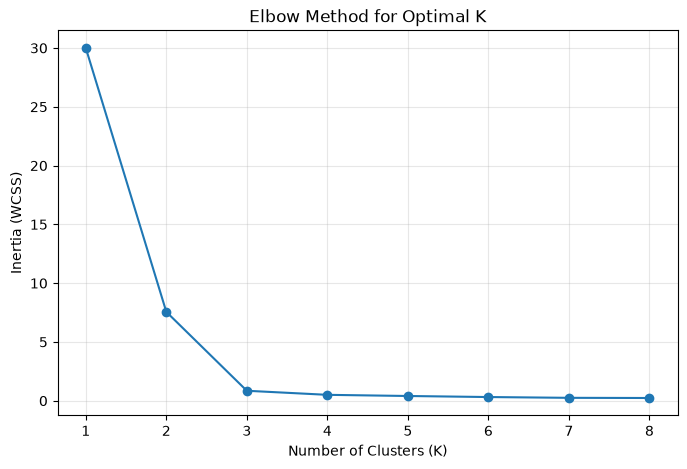

In [10]:
# Create a figure for the elbow curve
plt.figure(figsize=(8, 5))

# Plot cluster count against inertia
plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

# Add chart title and axis labels
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")

# Show every tested K value on the x-axis
plt.xticks(list(k_values))

# Add a grid for readability
plt.grid(True, alpha=0.3)

# Display the elbow curve
plt.show()

In [11]:
# Store the tested K values, starting at 2
# Silhouette Score requires at least two clusters
silhouette_k_values = range(2, 9)

# Create a list to store the scores
silhouette_scores = []

# Evaluate each candidate number of clusters
for k in silhouette_k_values:

    # Create a K-Means model
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    # Assign each customer to a cluster
    labels = model.fit_predict(X_scaled)

    # Calculate the average Silhouette Score
    score = silhouette_score(X_scaled, labels)

    # Store the score for later visualization
    silhouette_scores.append(score)

    # Print the score for the current K
    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.663
K = 3, Silhouette Score = 0.793
K = 4, Silhouette Score = 0.688
K = 5, Silhouette Score = 0.494
K = 6, Silhouette Score = 0.313
K = 7, Silhouette Score = 0.235
K = 8, Silhouette Score = 0.145


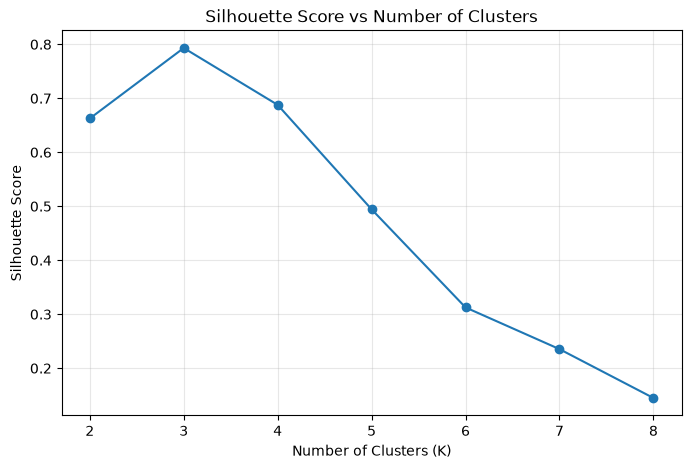

In [12]:
# Create a figure for comparing Silhouette Scores
plt.figure(figsize=(8, 5))

# Plot K against its Silhouette Score
plt.plot(
    list(silhouette_k_values),
    silhouette_scores,
    marker="o"
)

# Add chart title and axis labels
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

# Display the tested K values on the x-axis
plt.xticks(list(silhouette_k_values))

# Add a grid to improve readability
plt.grid(True, alpha=0.3)

# Display the chart
plt.show()

In [13]:
# Select three clusters as an initial choice
# Review the elbow curve and Silhouette Scores before finalizing K
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",  # Initialize centroids using K-Means++
    n_init=10,         # Run 10 initializations
    max_iter=300,      # Maximum iterations per run
    random_state=42    # Make results reproducible
)

# Fit the model and calculate the cluster assignments
kmeans.fit(X_scaled)

# Display basic training information
print("K-Means model trained successfully!")
print("Number of clusters:", kmeans.n_clusters)
print("Number of iterations:", kmeans.n_iter_)
print("Final inertia:", round(kmeans.inertia_, 3))

K-Means model trained successfully!
Number of clusters: 3
Number of iterations: 2
Final inertia: 0.847


In [14]:
# Store the predicted cluster number for every customer
df["Cluster"] = kmeans.labels_

# Display customer details and their assigned clusters
print(df.head(15))

    CustomerID  Annual_Income  Spending_Score  Cluster
0            1             15              80        2
1            2             18              75        2
2            3             20              85        2
3            4             22              78        2
4            5             25              82        2
5            6             40              40        0
6            7             42              45        0
7            8             45              42        0
8            9             48              38        0
9           10             50              44        0
10          11             70              20        1
11          12             75              25        1
12          13             78              18        1
13          14             85              15        1
14          15             90              22        1


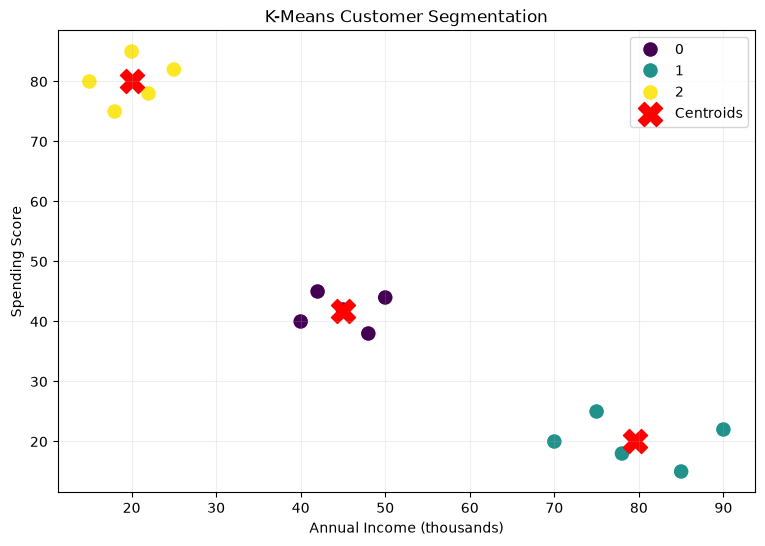

In [15]:
# Create a figure for the final cluster visualization
plt.figure(figsize=(9, 6))

# Plot customers, using different colors for their clusters
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    s=130
)

# Convert standardized centroid coordinates back
# to the original income and spending-score scales
centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Mark the centroids with red X symbols
plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    marker="X",
    s=300,
    color="red",
    label="Centroids"
)

# Add labels, title, legend, and grid
plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.legend()
plt.grid(True, alpha=0.2)

# Display the final cluster plot
plt.show()

In [16]:
# Group customers by their assigned cluster
# Calculate customer count and average feature values
cluster_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Income=("Annual_Income", "mean"),
    Average_Spending=("Spending_Score", "mean")
)

# Round the numerical results for readability
cluster_summary = cluster_summary.round(2)

# Display the cluster summary
print(cluster_summary)

         Number_of_Customers  Average_Income  Average_Spending
Cluster                                                       
0                          5            45.0              41.8
1                          5            79.6              20.0
2                          5            20.0              80.0


In [17]:
# Calculate the median income and spending score
# These values provide simple thresholds for descriptions
income_median = df["Annual_Income"].median()
spending_median = df["Spending_Score"].median()

# Calculate average income and spending score for each cluster
cluster_profile = df.groupby("Cluster").agg(
    Average_Income=("Annual_Income", "mean"),
    Average_Spending=("Spending_Score", "mean")
)

# Define a function to describe each cluster
def describe_cluster(row):

    # Determine whether the cluster's average income is high
    high_income = row["Average_Income"] >= income_median

    # Determine whether the cluster's average spending is high
    high_spending = row["Average_Spending"] >= spending_median

    # Return a descriptive segment name
    if high_income and high_spending:
        return "High Income, High Spending"

    elif high_income and not high_spending:
        return "High Income, Low Spending"

    elif not high_income and high_spending:
        return "Low Income, High Spending"

    else:
        return "Low Income, Low Spending"


# Apply the function to each cluster's summary
cluster_profile["Segment"] = cluster_profile.apply(
    describe_cluster,
    axis=1
)

# Display the segment descriptions
print(cluster_profile.round(2))

         Average_Income  Average_Spending                    Segment
Cluster                                                             
0                  45.0              41.8  High Income, Low Spending
1                  79.6              20.0  High Income, Low Spending
2                  20.0              80.0  Low Income, High Spending


In [18]:
# Create a DataFrame for a new customer
new_customer = pd.DataFrame({
    "Annual_Income": [43],
    "Spending_Score": [43]
})

# Transform the new customer's features using the
# same scaler that was fitted on the original dataset
new_customer_scaled = scaler.transform(new_customer)

# Predict which cluster the customer belongs to
predicted_cluster = kmeans.predict(new_customer_scaled)

# Extract the predicted cluster number
cluster_number = int(predicted_cluster[0])

# Display the new customer's information and prediction
print("New customer:", new_customer.iloc[0].to_dict())
print("Predicted cluster:", cluster_number)

# Retrieve the corresponding descriptive segment
print(
    "Predicted segment:",
    cluster_profile.loc[cluster_number, "Segment"]
)

New customer: {'Annual_Income': 43, 'Spending_Score': 43}
Predicted cluster: 0
Predicted segment: High Income, Low Spending


In [19]:
# Calculate the average Silhouette Score
# using the final model's cluster assignments
final_silhouette_score = silhouette_score(
    X_scaled,
    kmeans.labels_
)

# Display evaluation metrics
print("Final Model Evaluation")
print("----------------------")

# Display how well clusters are separated on average
print(f"Silhouette Score: {final_silhouette_score:.3f}")

# Display the sum of squared distances to centroids
print(f"Inertia: {kmeans.inertia_:.3f}")

# Display the number of iterations used
print(f"Iterations: {kmeans.n_iter_}")

Final Model Evaluation
----------------------
Silhouette Score: 0.793
Inertia: 0.847
Iterations: 2


In [20]:
# Display a concise summary of the clustering project
print("K-MEANS CUSTOMER SEGMENTATION")
print("=" * 35)

print("Total customers:", len(df))
print("Features used:", ["Annual_Income", "Spending_Score"])
print("Number of clusters:", kmeans.n_clusters)

print(
    "Silhouette Score:",
    round(final_silhouette_score, 3)
)

print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster profiles:")
print(cluster_profile.round(2))

print("\nProject completed successfully!")

K-MEANS CUSTOMER SEGMENTATION
Total customers: 15
Features used: ['Annual_Income', 'Spending_Score']
Number of clusters: 3
Silhouette Score: 0.793

Customers per cluster:
Cluster
0    5
1    5
2    5
Name: count, dtype: int64

Cluster profiles:
         Average_Income  Average_Spending                    Segment
Cluster                                                             
0                  45.0              41.8  High Income, Low Spending
1                  79.6              20.0  High Income, Low Spending
2                  20.0              80.0  Low Income, High Spending

Project completed successfully!
